# Actividad 1 — Clasificación de texto con Naive Bayes
**Aprendizaje Supervisado · Sesión 9 · Naive Bayes y árboles de clasificación**
**Estudiante:** Julian Emiliano Ortiz Rivero

**Qué haremos.** En la presentación vimos cómo Naive Bayes convierte el teorema de Bayes en un
clasificador, apoyándose en el supuesto "naive" de independencia condicional, y que existen versiones
distintas según el tipo de variable (gaussiana, multinomial, Bernoulli). Hoy aplicas las versiones de
**texto** (multinomial y Bernoulli) a un corpus de reseñas breves de dos temas: **cine** y **cocina**.

Trabaja **de forma individual**. Las celdas con `...` están incompletas: reemplaza los puntos
suspensivos con el código que falta (el comentario `✏️` te da una pista de qué se espera).

## Parte 0 — El corpus

Cada fila es una reseña breve (una cadena de 6 a 14 palabras) con su etiqueta `clase` (`cine` o
`cocina`). Cada documento mezcla palabras **propias del tema** (≈65% de las palabras) con palabras
**comunes** a ambos temas (adjetivos como "excelente", "aburrido", "caro"), tal como pasaría con
reseñas reales.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def genera_resenas(n_por_clase, semilla):
    rng = np.random.default_rng(semilla)
    vocab_cine = ["actuacion", "guion", "director", "pelicula", "escena", "camara",
                  "actor", "trama", "estreno", "taquilla", "efectos", "personaje"]
    vocab_cocina = ["receta", "sabor", "ingrediente", "horno", "sazon", "textura",
                     "plato", "cocina", "aroma", "porcion", "fuego", "especia"]
    vocab_comun = ["excelente", "bueno", "malo", "regular", "recomiendo", "aburrido",
                    "sorprendente", "lento", "rapido", "caro", "barato", "increible"]

    def doc(vocab_tema):
        n = rng.integers(6, 15)
        n_tema = max(2, int(n * 0.65)); n_comun = n - n_tema
        palabras = list(rng.choice(vocab_tema, n_tema)) + list(rng.choice(vocab_comun, n_comun))
        rng.shuffle(palabras)
        return " ".join(palabras)

    filas = [{"texto": doc(vocab_cine), "clase": "cine"} for _ in range(n_por_clase)]
    filas += [{"texto": doc(vocab_cocina), "clase": "cocina"} for _ in range(n_por_clase)]
    return pd.DataFrame(filas).sample(frac=1, random_state=semilla).reset_index(drop=True)


resenas = genera_resenas(300, semilla=2026)
print(resenas.shape)
resenas.head()


(600, 2)


,texto,clase
0,lento sabor bueno fuego fuego sorprendente por...,cocina
1,caro sorprendente sazon aroma bueno sazon rapi...,cocina
2,rapido actuacion regular escena escena caro so...,cine
3,barato cocina porcion ingrediente plato sazon ...,cocina
4,especia ingrediente rapido bueno textura incre...,cocina


In [2]:
print(resenas["clase"].value_counts())
vocabulario_total = set(" ".join(resenas["texto"]).split())
print("Palabras distintas en todo el corpus (vocabulario):", len(vocabulario_total))
print("Longitud promedio de reseña (palabras):", round(resenas["texto"].str.split().apply(len).mean(), 1))


clase
cocina    300
cine      300
Name: count, dtype: int64
Palabras distintas en todo el corpus (vocabulario): 36
Longitud promedio de reseña (palabras): 10.0


✏️ **Pregunta 0.1.** (a) ¿Cuántos documentos hay de cada clase? (b) ¿Cuántas palabras distintas tiene
el vocabulario completo? (c) Dado que cada reseña mezcla vocabulario del tema con palabras comunes a
ambos temas, ¿esperarías que el vocabulario de "cine" y el de "cocina" se traslapen mucho o poco?

**Respuesta:** Hay 300 documentos de cocina y 300 de cine. El vocabulario tiene 36 palabras distintas. Las dos clases comparten 12 palabras generales, mientras que el resto del vocabulario se relaciona con cada tema.

## Parte 1 — Vectorización y Naive Bayes multinomial  *(presentación A4, A7)*

`CountVectorizer` convierte cada reseña en un vector de **conteos** de palabras (bolsa de palabras).
`MultinomialNB` es la versión de Naive Bayes pensada justamente para conteos.


Tamaño del vocabulario aprendido: 36
Exactitud multinomial (prueba): 1.0
              precision    recall  f1-score   support

        cine       1.00      1.00      1.00        75
      cocina       1.00      1.00      1.00        75

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



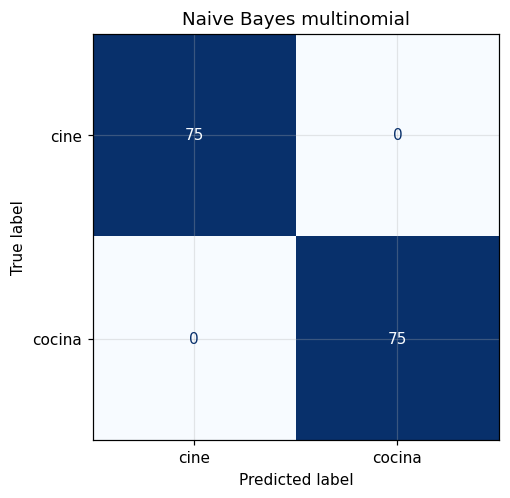

In [3]:
Xtr_txt, Xte_txt, ytr, yte = train_test_split(resenas["texto"], resenas["clase"],
                                               test_size=0.25, random_state=0, stratify=resenas["clase"])

vectorizador = CountVectorizer()
Xtr = vectorizador.fit_transform(Xtr_txt)
Xte = vectorizador.transform(Xte_txt)
print("Tamaño del vocabulario aprendido:", len(vectorizador.get_feature_names_out()))

mnb = MultinomialNB().fit(Xtr, ytr)
print("Exactitud multinomial (prueba):", round(mnb.score(Xte, yte), 3))
print(classification_report(yte, mnb.predict(Xte)))
ConfusionMatrixDisplay.from_estimator(mnb, Xte, yte, cmap="Blues", colorbar=False)
plt.title("Naive Bayes multinomial"); plt.show()


✏️ **Pregunta 1.1.** ¿Qué exactitud obtuvo `MultinomialNB` en el conjunto de prueba? ¿Te sorprende el
resultado, dado lo que respondiste en la Pregunta 0.1 sobre el traslape de vocabularios?

**Respuesta:** La exactitud fue de 1.00. El resultado es razonable porque las palabras propias de cocina y cine separan claramente las clases, aunque existan algunas palabras comunes.

## Parte 2 — Naive Bayes Bernoulli  *(presentación A4)*

`BernoulliNB` solo mira si cada palabra **aparece o no** (0/1), ignorando cuántas veces se repite.
Usamos `CountVectorizer(binary=True)` para obtener ese tipo de vector.


In [4]:
vectorizador_bin = CountVectorizer(binary=True)
Xtr_bin = vectorizador_bin.fit_transform(Xtr_txt)
Xte_bin = vectorizador_bin.transform(Xte_txt)

bnb = BernoulliNB().fit(Xtr_bin, ytr)
print("Exactitud Bernoulli (prueba):", round(bnb.score(Xte_bin, yte), 3))
print("Exactitud multinomial (prueba):", round(mnb.score(Xte, yte), 3))


Exactitud Bernoulli (prueba): 1.0
Exactitud multinomial (prueba): 1.0


✏️ **Pregunta 2.1.** Compara la exactitud de `BernoulliNB` con la de `MultinomialNB` de la Parte 1.
¿Son iguales, o una es mejor? Dado que las reseñas son cortas (6 a 14 palabras) y casi ninguna palabra
se repite dos veces dentro de una misma reseña, ¿por qué tendría sentido que ambas versiones dieran un
resultado muy parecido aquí?

**Respuesta:** Bernoulli también obtuvo una exactitud de 1.00. En estos documentos cortos hay pocas repeticiones, por lo que contar las palabras o registrar solamente su presencia produce casi la misma información.

## Parte 3 — Palabras más "típicas" de cada clase  *(presentación A8)*

`feature_log_prob_` guarda, para cada clase, el logaritmo de la probabilidad de cada palabra dado esa
clase. Las palabras con el log-probabilidad más alto dentro de una clase son las más "típicas" de ella.


In [5]:
palabras = np.array(vectorizador.get_feature_names_out())
for i, clase in enumerate(mnb.classes_):
    top5 = palabras[np.argsort(mnb.feature_log_prob_[i])[::-1][:5]]
    print(f"{clase}: {list(top5)}")


cine: ['escena', 'efectos', 'camara', 'personaje', 'director']
cocina: ['cocina', 'sazon', 'especia', 'plato', 'fuego']


✏️ **Pregunta 3.1.** Lista las 5 palabras más típicas de "cine" y de "cocina" que imprimió la celda
anterior. ¿Son palabras propias del tema (como esperarías) o palabras comunes? ¿Por qué las palabras
comunes (`excelente`, `bueno`, etc.) **no** aparecen entre las más típicas de ninguna clase?

**Respuesta:** En cine destacan escena, efectos, camara, personaje y director. En cocina aparecen cocina, sazon, especia, plato y fuego. Las palabras comunes tienen un peso parecido en ambas clases, por eso ayudan poco a distinguirlas.

## Parte 4 — Clasifica tus propios documentos  *(presentación A9–A10)*

Escribe **tres reseñas nuevas** (que no estén en el corpus) y observa qué predice cada modelo. Dos ya
están escritas como ejemplo; escribe la tercera con una mezcla deliberada de vocabulario de cine y de
cocina, para ver qué hace el modelo con un caso ambiguo.


In [6]:
documentos_nuevos = [
    "la actuacion y el guion de la pelicula fueron excelentes, el director logro una gran trama",
    "la receta tenia buen sabor pero el plato llego frio y con poca sazon",
    "el director preparo una receta en la cocina durante una escena de la pelicula",
]

for doc in documentos_nuevos:
    pred_m = mnb.predict(vectorizador.transform([doc]))[0]
    pred_b = bnb.predict(vectorizador_bin.transform([doc]))[0]
    print(f"Multinomial: {pred_m:8s}  Bernoulli: {pred_b:8s}   «{doc}»")


Multinomial: cine      Bernoulli: cine       «la actuacion y el guion de la pelicula fueron excelentes, el director logro una gran trama»
Multinomial: cocina    Bernoulli: cocina     «la receta tenia buen sabor pero el plato llego frio y con poca sazon»
Multinomial: cine      Bernoulli: cine       «el director preparo una receta en la cocina durante una escena de la pelicula»


✏️ **Pregunta 4.1.** (a) Para tus dos primeros documentos (claramente de un solo tema), ¿coinciden las
predicciones de ambos modelos con lo que esperabas? (b) ¿Qué predijeron los dos modelos para tu tercer
documento (el ambiguo)? ¿Les pareció razonable, dado qué palabras tiene de cada tema?

**Respuesta:** Los dos modelos clasificaron correctamente el texto de cine y el de cocina. El documento mezclado quedó como cine porque contiene director, escena y pelicula, frente a receta y cocina.

## Parte 5 — ¿Cuándo divergen Bernoulli y multinomial?

En la Parte 2 ambos modelos coincidieron porque las reseñas son cortas. La diferencia teórica entre
ambos aparece cuando una palabra se **repite** varias veces dentro de un mismo documento.


In [7]:
una_vez = "director bueno"
repetida = "director director director director director bueno"

for doc in [una_vez, repetida]:
    pm = mnb.predict_proba(vectorizador.transform([doc]))[0]
    pb = bnb.predict_proba(vectorizador_bin.transform([doc]))[0]
    print(f"«{doc}»")
    print(f"  Multinomial P(cine)={pm[list(mnb.classes_).index('cine')]:.4f}"
          f"   Bernoulli P(cine)={pb[list(bnb.classes_).index('cine')]:.4f}")


«director bueno»
  Multinomial P(cine)=0.9898   Bernoulli P(cine)=0.9897
«director director director director director bueno»
  Multinomial P(cine)=1.0000   Bernoulli P(cine)=0.9897


✏️ **Pregunta 5.1.** Interpreta: ¿en qué casos esperarías que Bernoulli y multinomial dieran resultados
muy distintos? Usa lo que observaste al repetir la palabra `director` cinco veces para explicar **por
qué** ocurre esa diferencia, en términos de qué información usa cada modelo.

**Respuesta:** La diferencia aparece cuando una palabra se repite. Multinomial considera la frecuencia, así que la probabilidad de cine pasó de 0.9898 a 1.0000 al repetir director. Bernoulli solo registra si la palabra está presente y mantuvo una probabilidad cercana a 0.9897.